Flygtninge og indvandrere  kept 5/7 · broke: ['DF', 'SF']
Klima og miljø             kept 7/8 · broke: ['ALT']
Økonomi og skat            kept 3/4 · broke: ['LA']


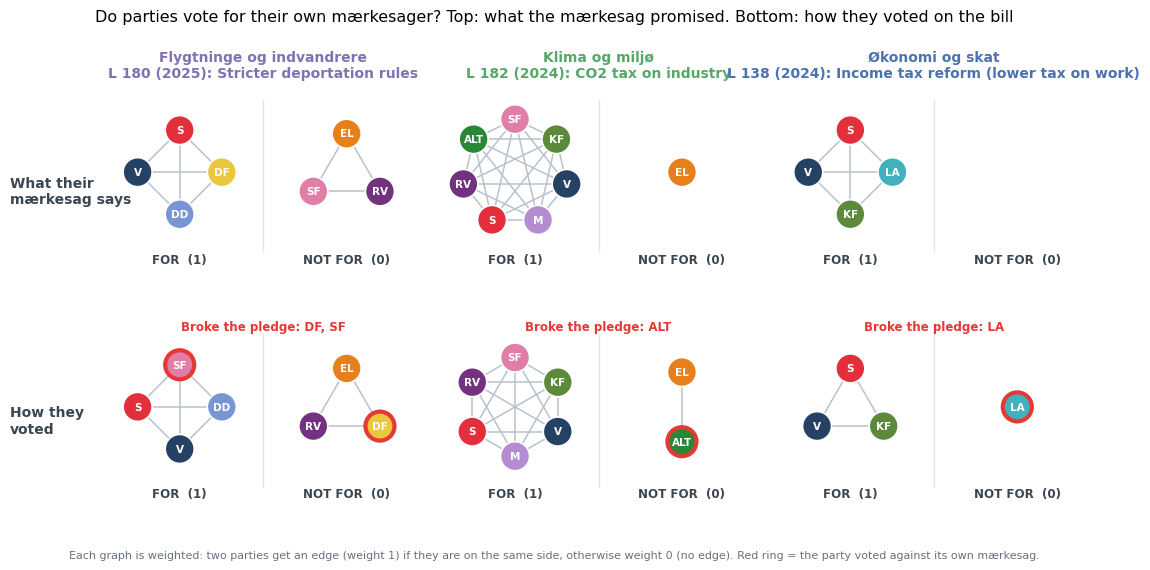

In [1]:
# --- Holder de deres mærkesager? Top 3 mærkesager: promise network vs. vote network ---
# Two weighted graphs per mærkesag (week 1: weighted networks):
#   PROMISE graph: weight 1 between two parties if their mærkesager point the same way on the bill, else 0
#   VOTE graph:    weight 1 between two parties if they voted the same way (for = 1, not for = 0), else 0
# Only weight-1 edges are drawn, so each graph splits into a "for" group and an "against" group.
import re
import itertools
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

MAPPE = "../../data/"      # notebook in notebooks/HolderDe/ – change if your notebook lies elsewhere
PARTIER = ["EL", "SF", "ALT", "RV", "S", "M", "V", "KF", "LA", "DD", "DF"]
FARVER = {"S": "#E32F3B", "V": "#254264", "M": "#B48CD2", "SF": "#E07EA8", "DD": "#7896D2", "LA": "#3FB2BE",
          "KF": "#5C8A3A", "EL": "#E6801A", "DF": "#EAC73E", "RV": "#733280", "ALT": "#2B8738"}

# 1 = the party's mærkesag supports what the bill does, 0 = the mærkesag is against it (from the mærkesag texts)
TOP3 = [
    {"maerkesag": "Flygtninge og indvandrere", "farve": "#8172B3", "afstemning_id": 10320,
     "lov": "L 180 (2025): Stricter deportation rules",
     "loefter": {"S": 1, "V": 1, "DF": 1, "DD": 1, "EL": 0, "SF": 0, "RV": 0}},
    {"maerkesag": "Klima og miljø", "farve": "#55A868", "afstemning_id": 9847,
     "lov": "L 182 (2024): CO2 tax on industry",
     "loefter": {"S": 1, "V": 1, "SF": 1, "RV": 1, "ALT": 1, "KF": 1, "M": 1, "EL": 0}},   # EL: wanted the rebate to big emitters cancelled
    {"maerkesag": "Økonomi og skat", "farve": "#4C72B0", "afstemning_id": 9656,
     "lov": "L 138 (2024): Income tax reform (lower tax on work)",
     "loefter": {"S": 1, "V": 1, "KF": 1, "LA": 1}},
]

# 2. How each party voted: Folketinget's official conclusion of the final vote
afst = pd.read_csv(MAPPE + "processed/afstemninger_2022_2026.csv", usecols=["afstemning_id", "konklusion"])
def partistemmer(tekst):
    tekst = re.sub(r"[A-ZÆØÅ][\wæøåé\.-]+(?: [A-ZÆØÅ][\wæøåé\.-]+)+ \([A-ZÆØÅ]+\)", "", str(tekst))  # drop single MPs
    dele = re.split(r"(?i)(for stemte|imod stemte|hverken for eller imod stemte)", tekst)
    ud = {}
    for etiket, indhold in zip(dele[1::2], dele[2::2]):
        for p in PARTIER:
            if re.search(rf"(?<!\w){p}(?!\w)", indhold):
                ud[p] = 1 if etiket.lower() == "for stemte" else 0      # for = 1, against/abstain = 0
    return ud
STEMMER = {i: partistemmer(k) for i, k in zip(afst["afstemning_id"], afst["konklusion"])}

def vaegtet_graf(vaerdi):
    """Weighted graph: weight 1 between two parties with the same value (both 1 or both 0), otherwise 0."""
    G = nx.Graph()
    G.add_nodes_from(vaerdi)
    for a, b in itertools.combinations(vaerdi, 2):
        G.add_edge(a, b, weight=int(vaerdi[a] == vaerdi[b]))
    return G

def placering(vaerdi):
    """'For' group on a small circle to the left, 'against' group to the right."""
    pos = {}
    for gruppe, cx in [(1, -1.15), (0, 1.15)]:
        medl = [p for p in PARTIER if vaerdi.get(p) == gruppe]
        for k, p in enumerate(medl):
            v = np.pi / 2 + 2 * np.pi * k / max(len(medl), 1)
            r = 0 if len(medl) == 1 else 0.38 + 0.05 * len(medl)
            pos[p] = (cx + r * np.cos(v), r * np.sin(v))
    return pos

def tegn(ax, G, pos, brudt=()):
    for a, b, d in G.edges(data=True):
        if d["weight"] == 1:
            ax.plot(*zip(pos[a], pos[b]), color="#b8c2cc", lw=1.1, zorder=1)
    for p in G.nodes:
        x, y = pos[p]
        ax.add_patch(Circle((x, y), 0.2, fc=FARVER[p], zorder=3,
                            ec="#e53935" if p in brudt else "white", lw=3 if p in brudt else 1.2))
        ax.text(x, y, p, ha="center", va="center", fontsize=7.5, fontweight="bold", color="white", zorder=4)
    ax.text(-1.15, -1.25, "FOR  (1)", ha="center", fontsize=8.5, fontweight="bold", color="#3c4650")
    ax.text(1.15, -1.25, "NOT FOR  (0)", ha="center", fontsize=8.5, fontweight="bold", color="#3c4650")
    ax.plot([0, 0], [-1.1, 1.0], color="#e3e7eb", lw=1, zorder=0)
    ax.set_xlim(-2.2, 2.2); ax.set_ylim(-1.45, 1.15); ax.set_aspect("equal"); ax.axis("off")

fig, akser = plt.subplots(2, 3, figsize=(11, 5.6))
for k, m in enumerate(TOP3):
    loefte = m["loefter"]
    stemt = {p: STEMMER[m["afstemning_id"]].get(p, 0) for p in loefte}        # same parties as in the promise graph
    brudt = [p for p in loefte if loefte[p] != stemt[p]]
    G_loefte, G_stemt = vaegtet_graf(loefte), vaegtet_graf(stemt)
    tegn(akser[0, k], G_loefte, placering(loefte))
    tegn(akser[1, k], G_stemt, placering(stemt), brudt)
    akser[0, k].set_title(f"{m['maerkesag']}\n{m['lov']}", fontsize=10, fontweight="bold", color=m["farve"], pad=8)
    akser[1, k].text(0, 1.05, ("Kept by all" if not brudt else "Broke the pledge: " + ", ".join(brudt)),
                     ha="center", fontsize=8.5, color="#2e7d32" if not brudt else "#e53935", fontweight="bold")
    print(f"{m['maerkesag']:26s} kept {len(loefte) - len(brudt)}/{len(loefte)} · broke: {brudt or '-'}")

fig.text(0.005, 0.66, "What their\nmærkesag says", fontsize=10, fontweight="bold", color="#3c4650", va="center")
fig.text(0.005, 0.25, "How they\nvoted", fontsize=10, fontweight="bold", color="#3c4650", va="center")
fig.text(0.5, 0.005, "Each graph is weighted: two parties get an edge (weight 1) if they are on the same side, otherwise weight 0 (no edge). "
         "Red ring = the party voted against its own mærkesag.", ha="center", fontsize=8, color="#66717d")
fig.subplots_adjust(left=0.09, right=0.99, top=0.88, bottom=0.05, wspace=0.05, hspace=0.02)
fig.suptitle("Do parties vote for their own mærkesager? Top: what the mærkesag promised. Bottom: how they voted on the bill",
             fontsize=11.5, x=0.5, y=0.985)
fig.savefig("fig3_top3_maerkesager.png", dpi=300, bbox_inches="tight")
plt.show()
